# Name : Manthan Madankar
# Class : C2-B2
# Roll no : 16
# ML Practical 9

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import (silhouette_score,davies_bouldin_score,calinski_harabasz_score)
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import linkage,dendrogram
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8,5)
df=pd.read_csv('Wholesale customers data - Wholesale customers data.csv')

In [ ]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [ ]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [ ]:
df.shape

(440, 8)

In [ ]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [ ]:
features=[
    'Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen'
]
X=df[features].copy()
display(X.head())
print('No.of records used for clustering=',len(X))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


No.of records used for clustering= 440


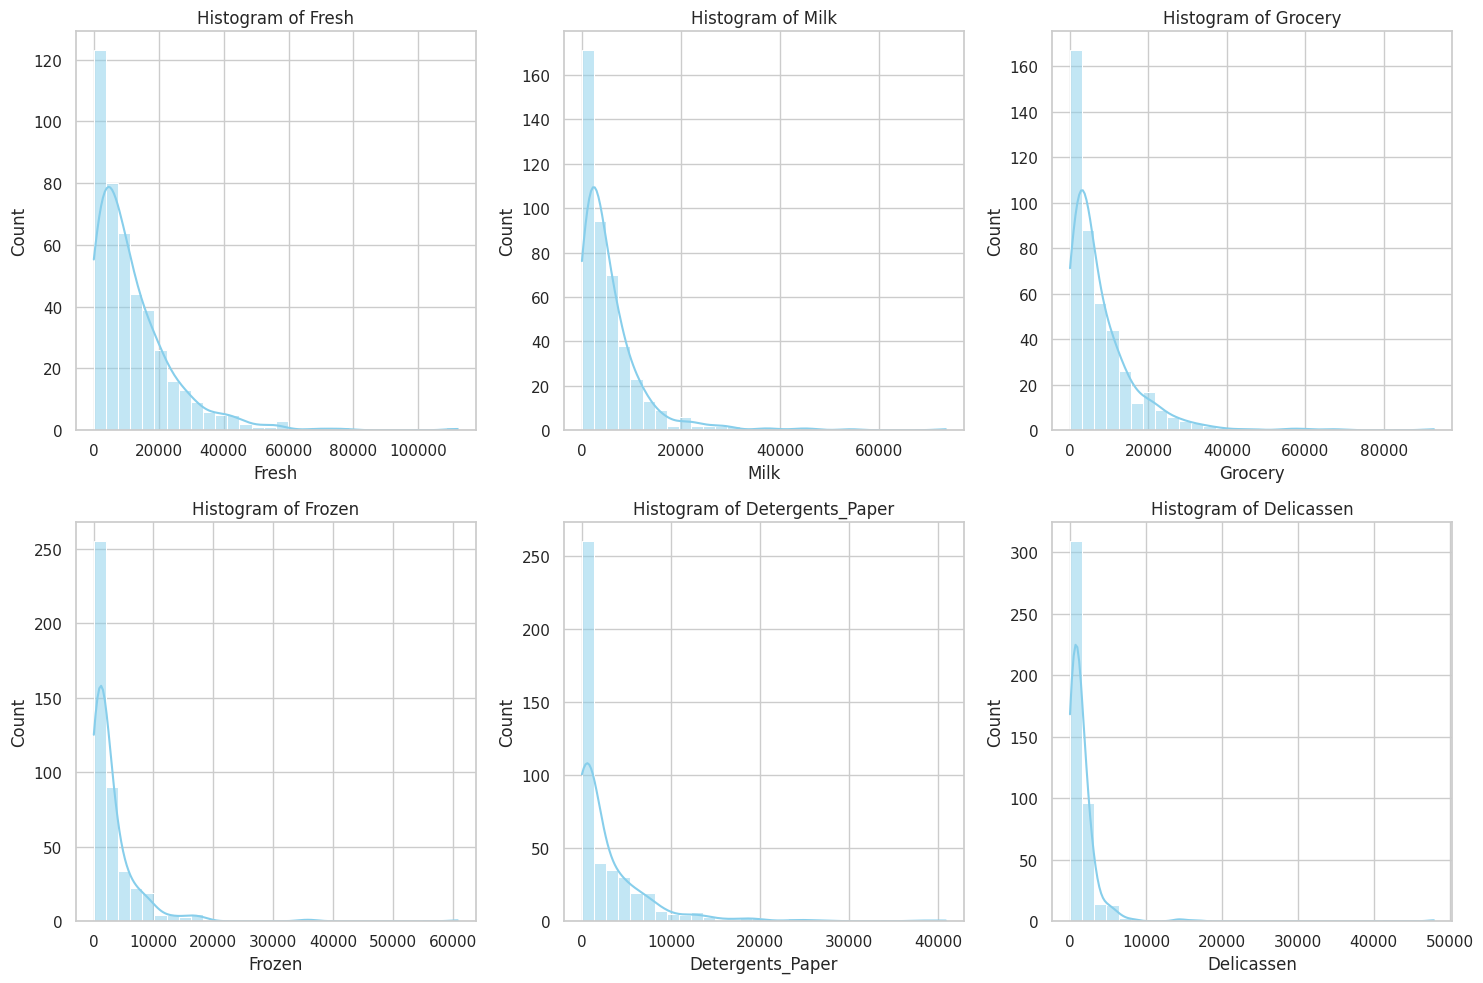

In [ ]:
plt.figure(figsize=(15, 10))
for i, feature in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[feature], kde=True, bins=30, color='skyblue')
    plt.title(f'Histogram of {feature}')
plt.tight_layout()
plt.show()


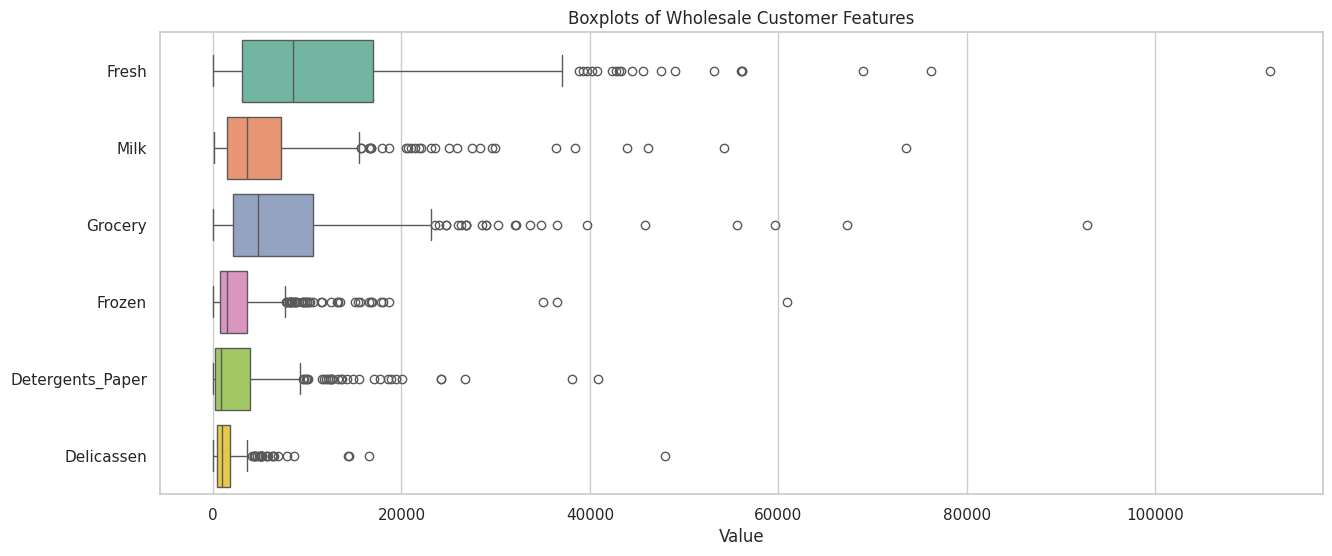

In [ ]:
plt.figure(figsize=(15, 6))
sns.boxplot(data=df[features], orient='h', palette='Set2')
plt.title('Boxplots of Wholesale Customer Features')
plt.xlabel('Value')
plt.show()


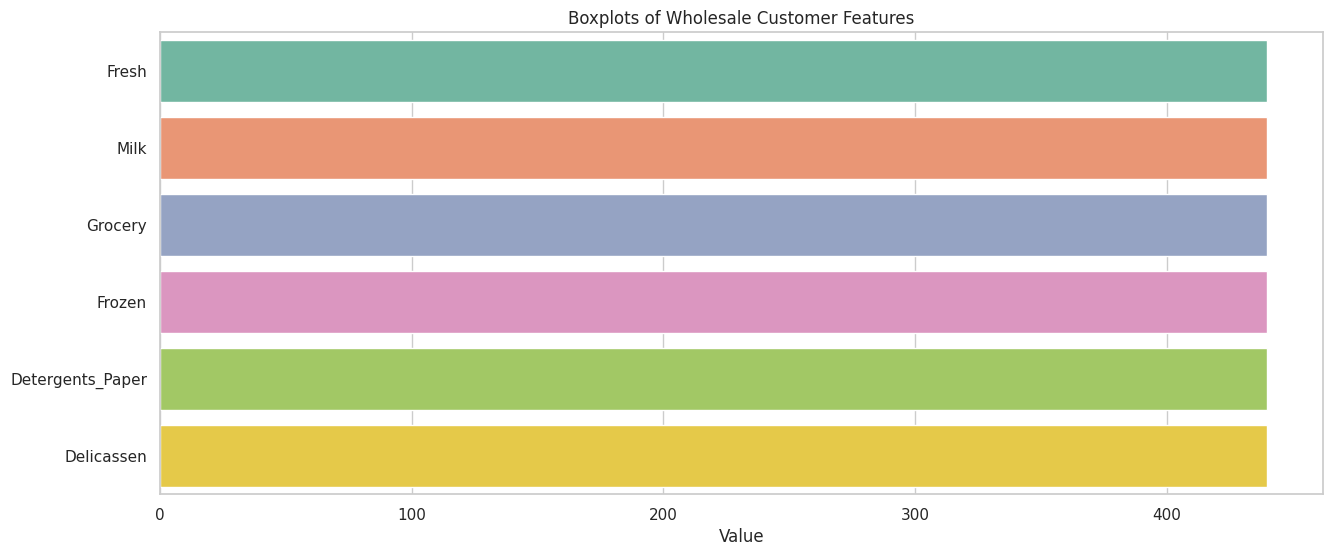

In [ ]:
plt.figure(figsize=(15, 6))
sns.countplot(data=df[features], orient='h', palette='Set2')
plt.title('Boxplots of Wholesale Customer Features')
plt.xlabel('Value')
plt.show()


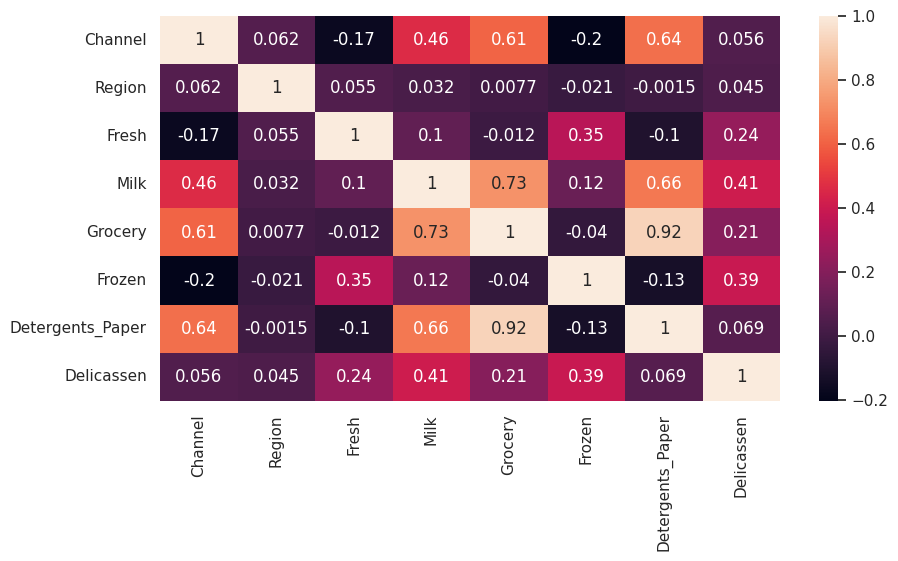

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(df.corr(),annot=True)
plt.show()

<Figure size 1000x500 with 0 Axes>

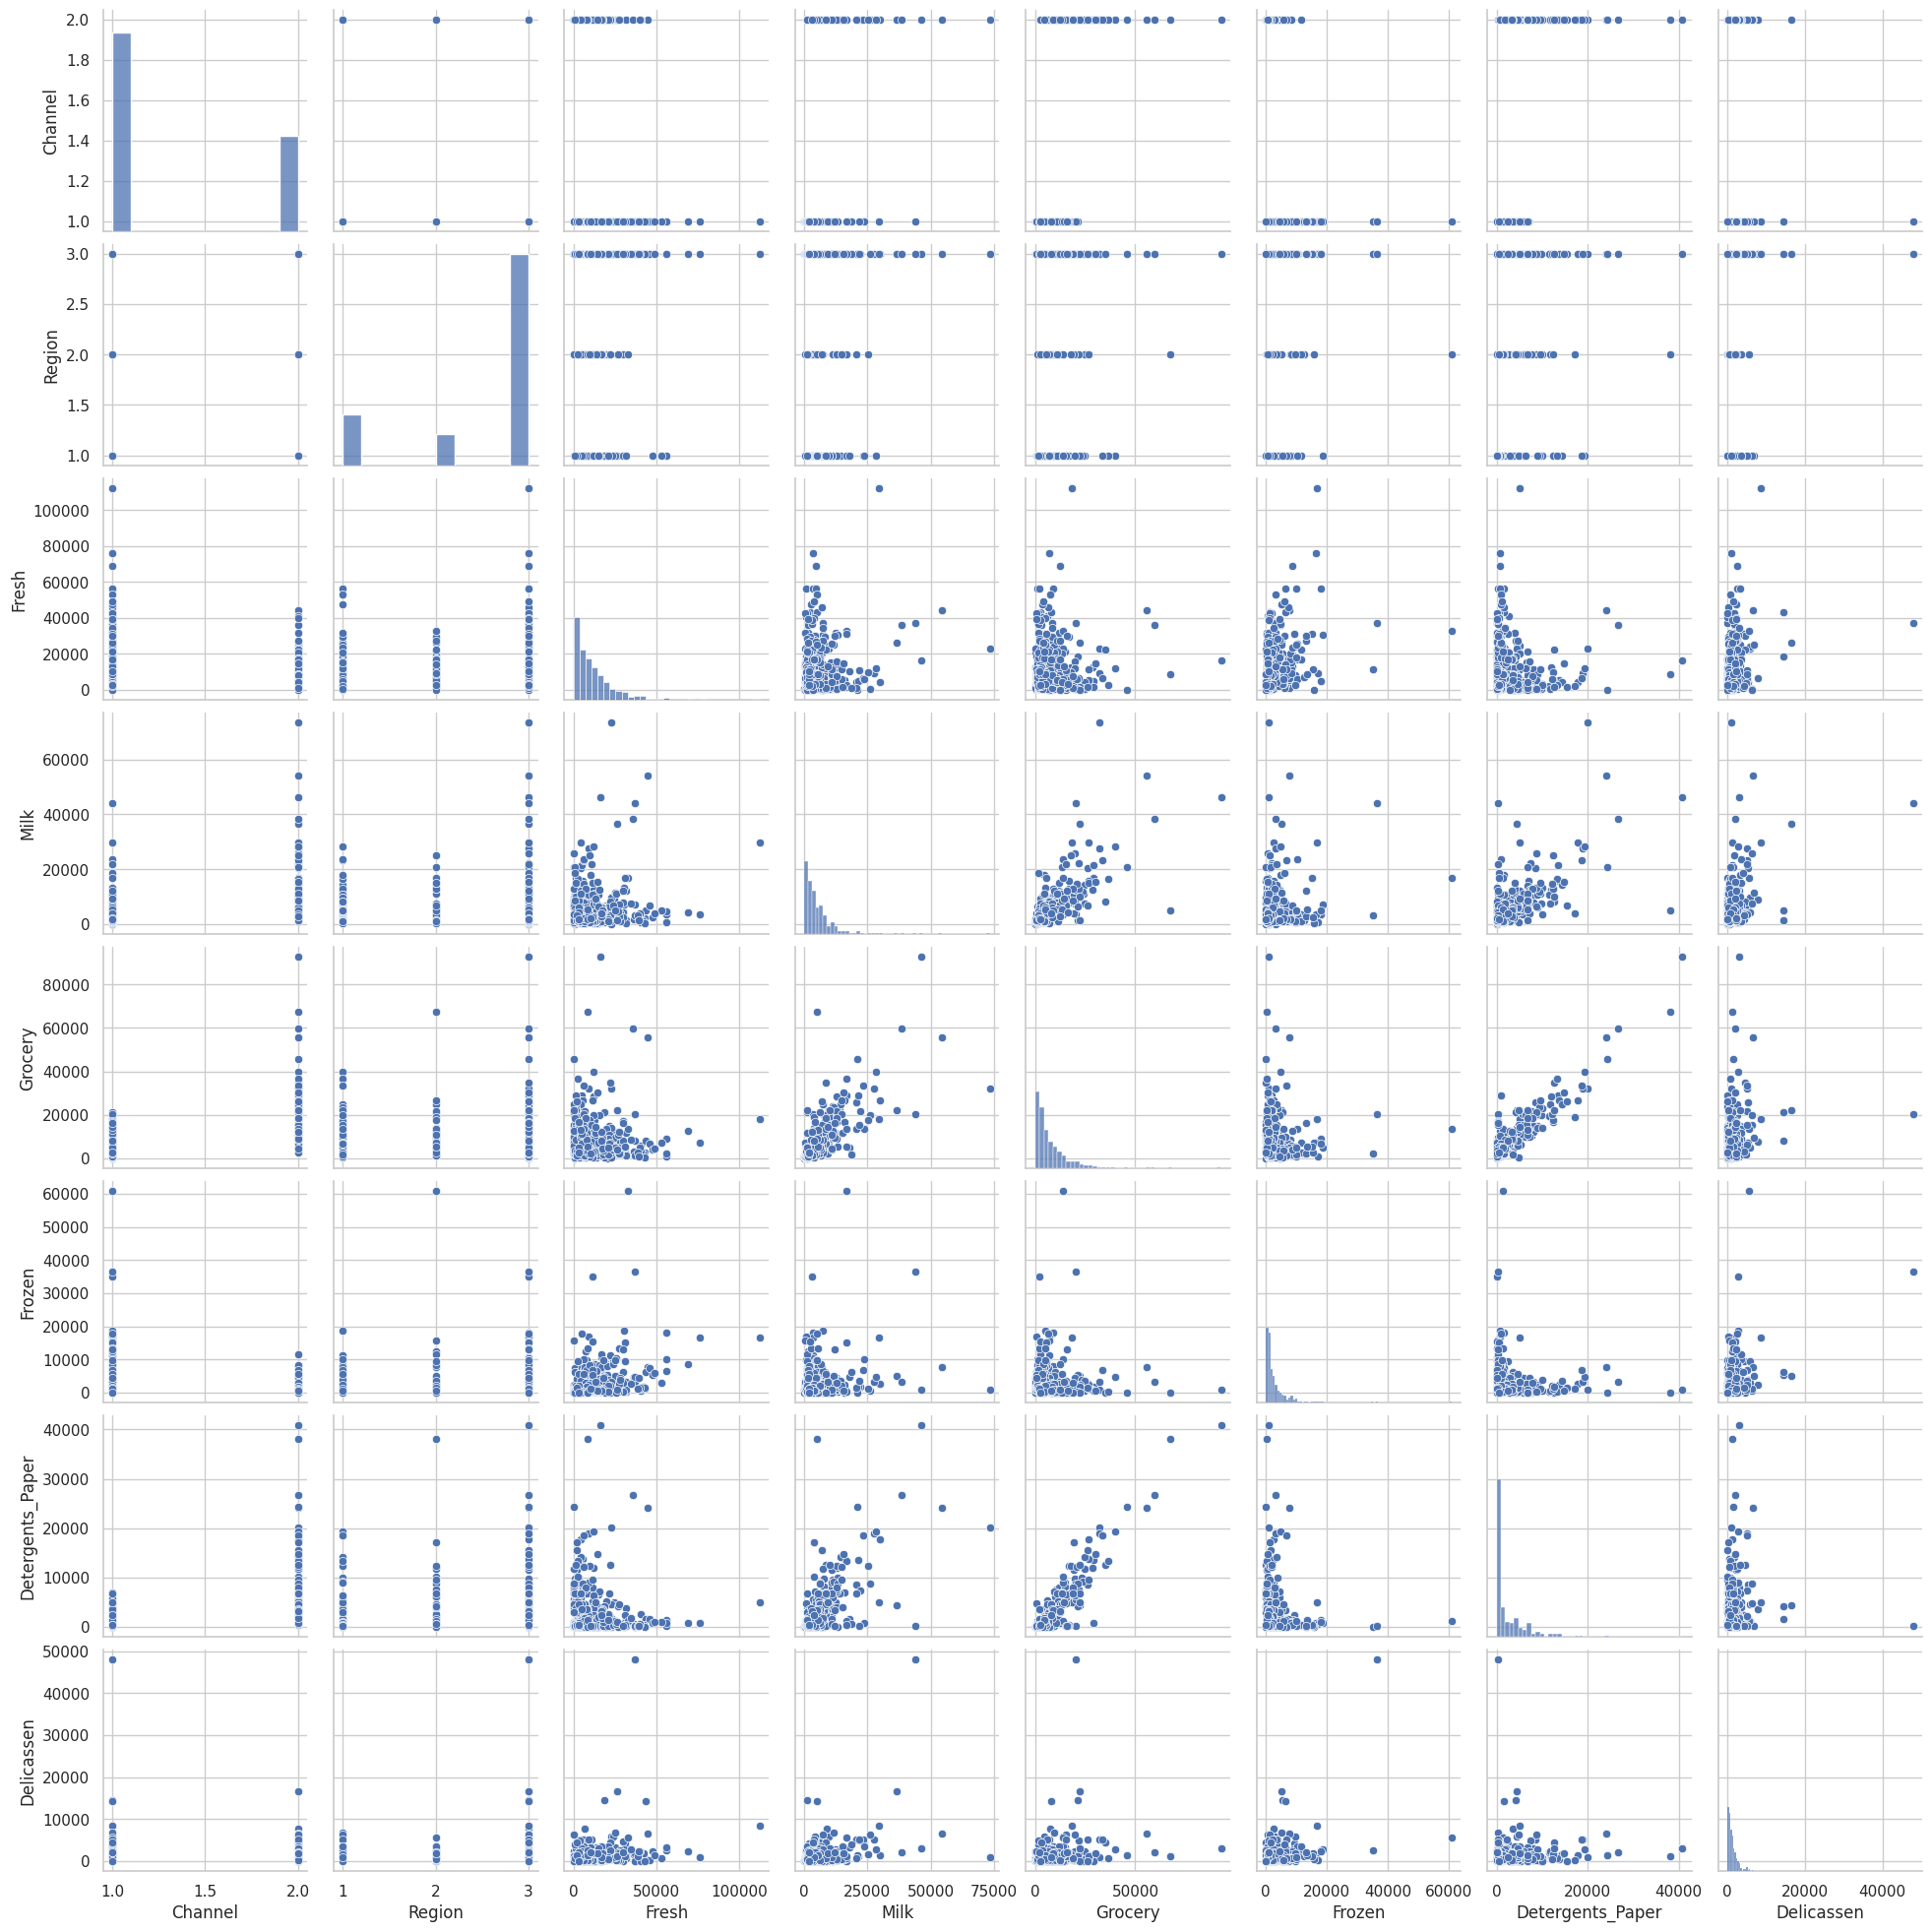

In [ ]:
plt.figure(figsize=(10,5))
sns.pairplot(df)
plt.show()

In [ ]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
X_scaled_df=pd.DataFrame(X_scaled,columns=features,index=X.index)
print('First five scaled records:',X_scaled_df.head())

First five scaled records:       Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
0  0.052933  0.523568 -0.041115 -0.589367         -0.043569   -0.066339
1 -0.391302  0.544458  0.170318 -0.270136          0.086407    0.089151
2 -0.447029  0.408538 -0.028157 -0.137536          0.133232    2.243293
3  0.100111 -0.624020 -0.392977  0.687144         -0.498588    0.093411
4  0.840239 -0.052396 -0.079356  0.173859         -0.231918    1.299347


In [ ]:
wcss=[]
k_values=range(1,11)
for k in k_values:
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

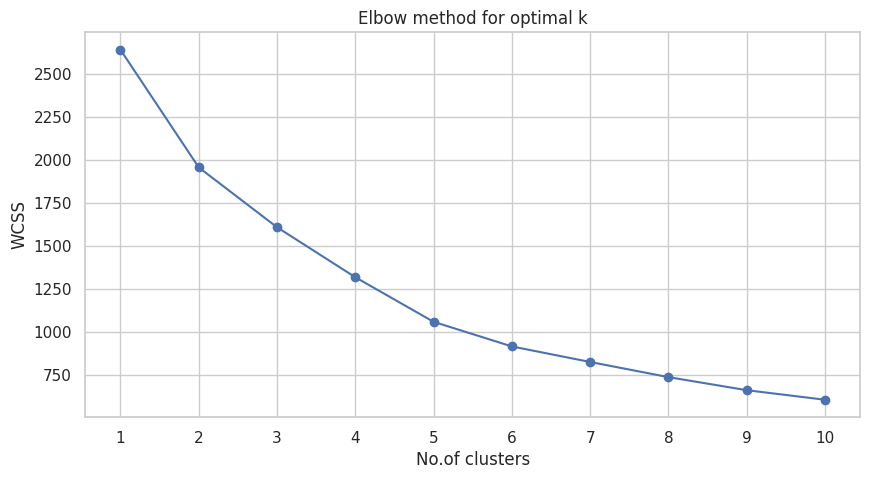

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(list(k_values),wcss,marker='o')
plt.xlabel('No.of clusters')
plt.ylabel('WCSS')
plt.title('Elbow method for optimal k')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
silhouette_values=[]
for k in range(2,11):
    model=KMeans(n_clusters=k,random_state=42,n_init=10)
    labels=model.fit_predict(X_scaled)
    score=silhouette_score(X_scaled,labels)
    silhouette_values.append(score)
silhouette_table=pd.DataFrame({'No.of clusters':list(range(2,11)),'Silhouette score':silhouette_values})
display(silhouette_table)

,No.of clusters,Silhouette score
0,2,0.547215
1,3,0.548287
2,4,0.348471
3,5,0.369040
4,6,0.378229
5,7,0.334282
6,8,0.320116
7,9,0.309028
8,10,0.311214


In [ ]:
suggested_k=int(
    silhouette_table.loc[silhouette_table['Silhouette score'].idxmax(),'No.of clusters']
)
print('K suggested values:',suggested_k)

K suggested values: 3


In [ ]:
K=suggested_k
kmeans_model=KMeans(n_clusters=K,random_state=42,n_init=10)
kmeans_labels=kmeans_model.fit_predict(X_scaled)

In [ ]:
df_kmeans=df.copy()
df_kmeans['KMeans_Cluster']=kmeans_labels
print('KMeans clustering completed')
print('No of customers in each cluster:')
print(df_kmeans['KMeans_Cluster'].value_counts().sort_index())
display(df_kmeans.head())

KMeans clustering completed
No of customers in each cluster:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [ ]:
hierarchical_model=AgglomerativeClustering(
    n_clusters=K,metric='euclidean',linkage='ward'
)
hierarchical_labels=hierarchical_model.fit_predict(X_scaled)

In [ ]:
df_hierarchical=df.copy()
df_hierarchical['Hierarchical_Cluster']=hierarchical_labels
print('Hierarchical clustering completed.')
print('No of customers in each cluster:')
print(df_hierarchical['Hierarchical_Cluster'].value_counts().sort_index())
display(df_hierarchical.head())

Hierarchical clustering completed.
No of customers in each cluster:
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


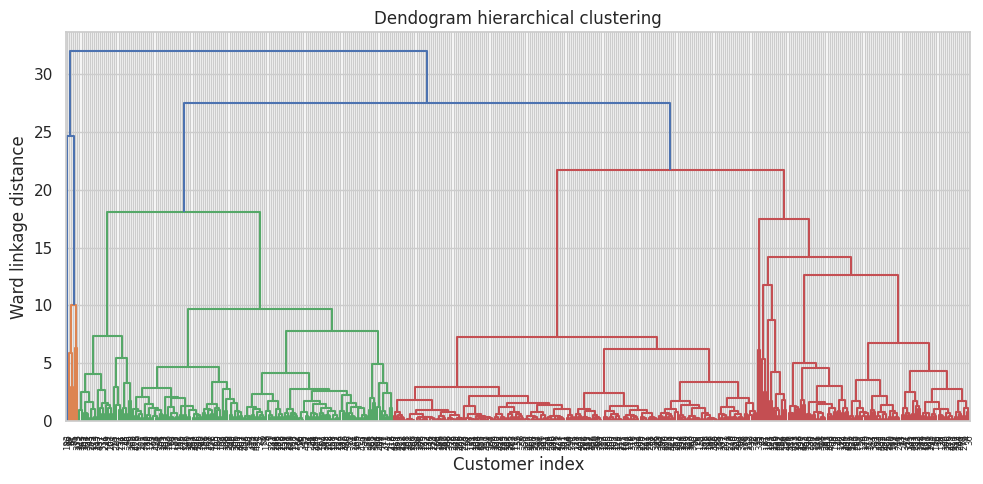

In [ ]:
Z=linkage(X_scaled,method='ward')
plt.figure(figsize=(10,5))
dendrogram(Z,leaf_rotation=90,leaf_font_size=6)
plt.title('Dendogram hierarchical clustering')
plt.xlabel('Customer index')
plt.ylabel('Ward linkage distance')
plt.tight_layout()
plt.show()

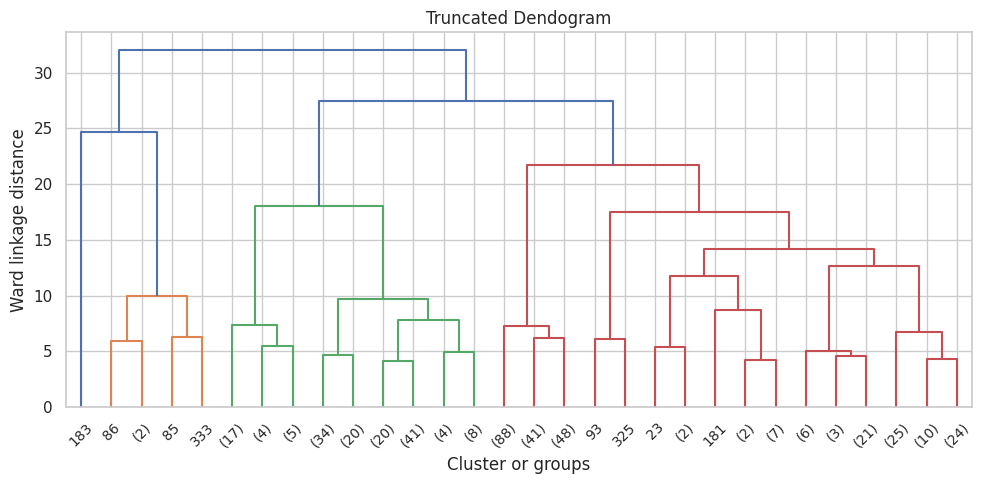

In [ ]:
plt.figure(figsize=(10,5))
dendrogram(Z,truncate_mode='lastp',p=30,show_leaf_counts=True,leaf_rotation=45)
plt.title('Truncated Dendogram')
plt.xlabel('Cluster or groups')
plt.ylabel('Ward linkage distance')
plt.tight_layout()
plt.show()

In [ ]:
pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_scaled)
print('Explained variance ratio:',round(pca.explained_variance_ratio_.sum()*100,2),'%')
plot_df=pd.DataFrame({'PC1':X_pca[:,0],'PC2':X_pca[:,1],
'KMeans_Cluster':kmeans_labels.astype(str),'Hierarchical_Cluster':hierarchical_labels.astype(str)})
display(plot_df.head())

Explained variance ratio: 72.46 %


,PC1,PC2,KMeans_Cluster,Hierarchical_Cluster
0,0.193291,-0.305100,1,2
1,0.434420,-0.328413,1,2
2,0.811143,0.815096,1,2
3,-0.778648,0.652754,1,1
4,0.166287,1.271434,1,1


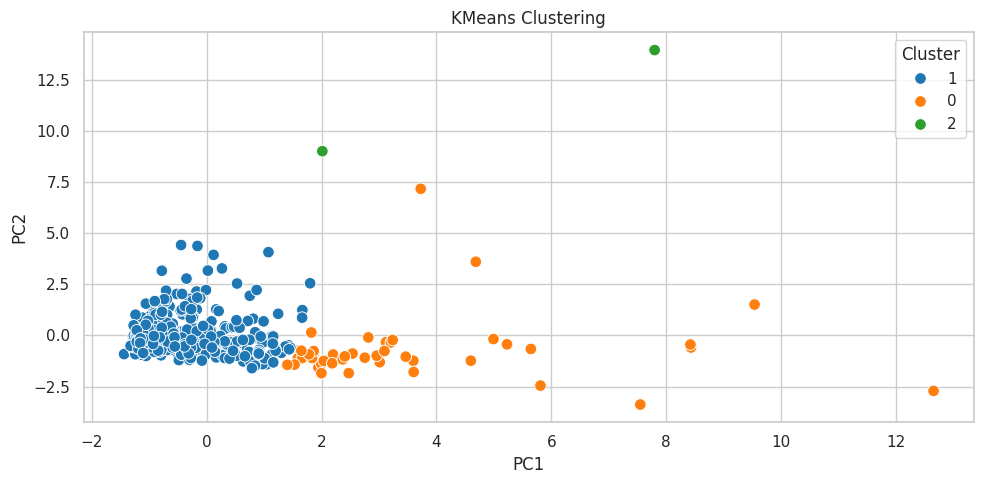

In [ ]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=plot_df,x='PC1',y='PC2',hue='KMeans_Cluster',palette='tab10',s=70)
plt.title('KMeans Clustering')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [ ]:
def evaluate_clustering(X_data,labels,model_name):
  return {
      'Algorithm':model_name,
      'Number of clusters':len(set(labels)),
      'Silhouette Score':silhouette_score(X_data,labels),
      'Davies-Bouldin Score':davies_bouldin_score(X_data,labels),
      'Calinski-Harabasz Score':calinski_harabasz_score(X_data,labels)
  }


In [ ]:
comparison_size=pd.DataFrame({
    'K-Means':pd.Series(kmeans_labels).value_counts().sort_index(),
    'Hierarchical':pd.Series(hierarchical_labels).value_counts().sort_index()
}).fillna(0).astype(int)
print('cluster size')
display(comparison_size)

cluster size


,K-Means,Hierarchical
0,45,6
1,393,281
2,2,153


In [ ]:
kmeans_profile=df[features].copy()
kmeans_profile['Cluster']=kmeans_labels

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00


In [ ]:
kmeans_means=kmeans_profile.groupby('Cluster')[features].mean().round(2)
display(kmeans_means)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00


In [ ]:
cluster_distribution=pd.DataFrame({
    'Customer Count':pd.Series(kmeans_labels).value_counts().sort_index(),
})
cluster_distribution['Percentage']=(
    cluster_distribution['Customer Count']/len(df)*100).round(2)
print('cluster distribution')
display(cluster_distribution)

cluster distribution


,Customer Count,Percentage
0,45,10.23
1,393,89.32
2,2,0.45


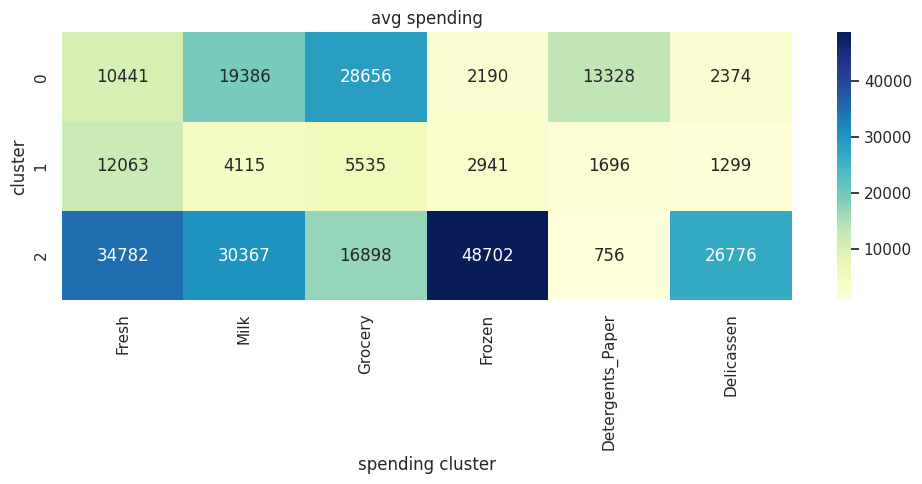

In [ ]:
plt.figure(figsize=(10,5))
sns.heatmap(kmeans_means,annot=True,fmt='.0f',cmap='YlGnBu')
plt.title('avg spending')
plt.xlabel('spending cluster')
plt.ylabel('cluster')
plt.tight_layout()
plt.show()

In [ ]:
channel_mix=pd.crosstab(df['Channel'],kmeans_labels,normalize='columns')*100
channel_mix.columns=[f'Cluster {c}' for c in channel_mix.columns]
display(channel_mix.round(2))

,Cluster 0,Cluster 1,Cluster 2
Channel,,,
1,2.22,75.06,100.0
2,97.78,24.94,0.0
